# Face Recognition under Challenging Image Conditions

The notebook has three parts. Reusable code lives in `src/`; baseline evaluation, final comparison, the leakage audit and the PDF report are separate scripts in `scripts/`.

Run order:

1. **Part 1** of this notebook: dataset split
2. `python -m scripts.baseline_evaluation`: pre-trained model on the test set, recorded before any training
3. **Part 2**: fine-tuning and KNN
4. **Part 3**: inference with the saved model
5. `python -m scripts.final_evaluation`, `python -m scripts.check_data_leakage`, `python -m scripts.generate_report`

In [1]:
import json
import time

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from src.config import PROJECT_ROOT
from src.logging_config import configure_logging

configure_logging("notebook")
pd.set_option("display.width", 140)

# Part 1: Dataset Split, 80% Train and 20% Test

`Images.zip` has eight people, each with a `high_quality` folder (frames from one close-up video) and a `low_quality` folder (small CCTV-style crops). The images are already face crops.

Neighbouring video frames are almost the same picture, so the split is done on **segments**: runs of up to 50 consecutive frames, at least 10 per folder. About 20% of each folder's segments go to test, and about 15% of the rest become a validation set inside the training portion. Training images that still look like a near-copy of a test image (thumbnail cosine ≥ 0.95) are dropped. The test set is never changed.

The result is copied to `data/train/<person>/high_quality|low_quality` and `data/test/<person>/high_quality|low_quality`, the same layout as the original.

In [2]:
from src.config import RAW_DATA_DIR, TEST_DIR, TRAIN_DIR, SplitConfig
from src.dataset import (copy_split, mark_exclusions, save_manifests, scan_dataset, split_dataset, summarize_split,
                         verify_split)

split_config = SplitConfig()
inventory = scan_dataset(RAW_DATA_DIR)
inventory.pivot_table(index="identity", columns="quality", values="source_id", aggfunc="count", margins=True, margins_name="total")

2026-10-23 11:08:31 [info     ] dataset_scanned                  [src.dataset] identities=8 images=22286 unreadable=154


quality,high_quality,low_quality,total
identity,,,
ananthu,845,3778,4623
firoz,758,987,1745
mujeeb,648,992,1640
ruvais,128,998,1126
sebin,411,1780,2191
shinjil,273,1537,1810
suresh,838,6905,7743
thomas,567,841,1408
total,4468,17818,22286


### Invalid images, duplicates and image sizes

In [3]:
inventory = mark_exclusions(inventory)
inventory["exclusion_reason"].fillna("usable").value_counts().to_frame("images")

2026-10-23 11:08:32 [info     ] exclusions_marked                [src.dataset] exact_duplicate=178 unreadable=154


,images
exclusion_reason,
usable,21954
exact_duplicate,178
unreadable,154


In [4]:
readable = inventory[inventory["readable"]]
readable.groupby("quality")[["width", "height"]].agg(["min", "median", "max"])

width             height            
               min median  max    min median  max
quality                                          
high_quality    19  359.0  460     23  444.0  631
low_quality      7   28.0  355     11   50.0  566

### Segment-level split

Every excluded file is kept in the excluded manifest with its reason.

In [5]:
train_df, test_df, excluded_df = split_dataset(inventory, split_config)
split_summary = summarize_split(train_df, test_df, excluded_df, split_config)
pd.Series(split_summary["excluded_by_reason"], name="images").to_frame()

2026-10-23 11:09:08 [info     ] dataset_split_complete           [src.dataset] excluded=2440 test=4418 train=13143 validation=2285


,images
near_duplicate_of_test,1602
near_duplicate_of_validation,506
exact_duplicate,178
unreadable,154


In [6]:
split_counts = pd.concat([train_df, test_df]).pivot_table(
    index=["identity", "quality"], columns="subset", values="source_id", aggfunc="count", fill_value=0
)[["train", "validation", "test"]]
split_counts["test_share"] = (split_counts["test"] / split_counts.sum(axis=1)).round(3)
split_counts

subset                 train  validation  test  test_share
identity quality                                          
ananthu  high_quality    489          75   145       0.205
         low_quality    2345         414   733       0.210
firoz    high_quality    380          63   150       0.253
         low_quality     553         109   200       0.232
mujeeb   high_quality    148           5   102       0.400
         low_quality     544          99   200       0.237
ruvais   high_quality     68          12    24       0.231
         low_quality     677          99   200       0.205
sebin    high_quality    245          42    82       0.222
         low_quality    1060         202   356       0.220
shinjil  high_quality    177          23    54       0.213
         low_quality    1007         161   320       0.215
suresh   high_quality    328          63   188       0.325
         low_quality    4177         766  1388       0.219
thomas   high_quality    387          50   117       0.211
         low_quality     558         102   159       0.194

### Copy into data/train and data/test

In [7]:
train_df, test_df = copy_split(train_df, test_df)
verify_split(train_df, test_df)

2026-10-23 11:23:24 [info     ] split_copied                     [src.dataset] folder=C:\Users\hafiz\face-recognition-project\data\train images=15428


2026-10-23 11:24:17 [info     ] split_copied                     [src.dataset] folder=C:\Users\hafiz\face-recognition-project\data\test images=4418


2026-10-23 11:24:17 [info     ] split_verified                   [src.dataset] test=4418 train=15428


{'shared_source_id': 0,
 'shared_path': 0,
 'shared_sha256': 0,
 'shared_segment': 0,
 'shared_validation_train_segments': 0,
 'test_identities_missing_from_train': 0}

In [8]:
pd.DataFrame({
    folder.name: {f"{person.name}/{quality.name}": sum(1 for _ in quality.iterdir())
                  for person in sorted(folder.iterdir()) for quality in sorted(person.iterdir())}
    for folder in (TRAIN_DIR, TEST_DIR)
})

,train,test
ananthu/high_quality,564,145
ananthu/low_quality,2759,733
firoz/high_quality,443,150
firoz/low_quality,662,200
mujeeb/high_quality,153,102
mujeeb/low_quality,643,200
ruvais/high_quality,80,24
ruvais/low_quality,776,200
sebin/high_quality,287,82
sebin/low_quality,1262,356


In [9]:
save_manifests(train_df, test_df, excluded_df, split_summary)
pd.Series({
    "train images": split_summary["subset_counts"]["train"],
    "validation images": split_summary["subset_counts"]["validation"],
    "test images": split_summary["subset_counts"]["test"],
    "test share at segment split": split_summary["test_fraction_at_split"],
    "test share after near-duplicate removal": split_summary["test_fraction_of_kept"],
    "excluded images": len(excluded_df),
}).to_frame("value")

2026-10-23 11:24:18 [info     ] manifests_saved                  [src.dataset] directory=C:\Users\hafiz\face-recognition-project\data\manifests


,value
train images,13143.0000
validation images,2285.0000
test images,4418.0000
test share at segment split,0.2012
test share after near-duplicate removal,0.2226
excluded images,2440.0000


**Before Part 2:** run `python -m scripts.baseline_evaluation` from the project root so the pre-trained baseline is recorded before any fine-tuning.

# Part 2: Model Training, Fine-Tuning and KNN

**Backbone.** InsightFace's IResNet-50 ArcFace model (`w600k_r50.onnx` from the `buffalo_l` pack, trained on WebFace600K) is rebuilt as a PyTorch module, and its weights are copied in from the ONNX file. The ONNX file is inference-only; the PyTorch copy is trainable and produces the same embeddings.

**Objective.** An ArcFace additive-angular-margin head over the 8 identities. There are too few identities for triplet mining to be informative, and a margin classifier is the objective the backbone was originally trained with. The head starts from each identity's mean pre-trained embedding.

**What is trained.** `layer4`, `bn2`, `fc` and `features`. The first three stages stay frozen. BatchNorm running statistics stay fixed.

**Augmentation.** Each training face gets one random change in memory (none, bright, dark, contrast, grayscale or shadow) and a horizontal flip half of the time. Nothing extra is written to disk.

**Selection.** The checkpoint with the best validation-pair ROC-AUC becomes `best_model.pt`. KNN neighbour count and the unknown-identity threshold also come from validation data only.

In [10]:
from src.classifier import build_knn, save_classifier, select_neighbors
from src.config import (AUGMENTATIONS, BEST_MODEL, CHART_DIR, KNN_CLASSIFIER, METRICS_DIR, TRAINING_SUMMARY,
                        VALIDATION_PAIRS, DetectionConfig, EvaluationConfig, TrainingConfig)
from src.dataset import load_manifests, verify_split
from src.detection import FaceDetector, crop_face, read_image
from src.embeddings import load_embedding_model, load_pretrained_arcface, onnx_agreement
from src.evaluation import attach_detections, embed_faces, load_or_create_pairs, usable_faces
from src.metrics import pair_scores, select_threshold
from src.plots import plot_training_history
from src.training import ArcFaceHead, fine_tune, set_seed, set_trainable_layers, weight_change_summary

if not (METRICS_DIR / "baseline_metrics.json").exists():
    raise RuntimeError("Run `python -m scripts.baseline_evaluation` first so the baseline is recorded before fine-tuning.")

train_df, test_df = load_manifests()
verify_split(train_df, test_df)

training_config = TrainingConfig.for_available_hardware()
detection_config = DetectionConfig()
set_seed(training_config.random_seed)
pd.Series(training_config.to_dict(), name="value").to_frame()

2026-10-23 11:25:33 [info     ] split_verified                   [src.dataset] test=4418 train=15428


,value
image_size,112
batch_size,64
epochs,10
learning_rate,0.0001
head_learning_rate,0.001
weight_decay,0.0005
optimizer,adamw
scheduler,cosine
embedding_dimension,512
arcface_scale,32.0


### Face detection on training and validation images

In [11]:
detector = FaceDetector(config=detection_config, device=training_config.device)
detected = {
    subset: attach_detections(train_df[train_df["subset"] == subset], subset, detector)
    for subset in ("train", "validation")
}
pd.DataFrame({subset: frame["detection_status"].value_counts() for subset, frame in detected.items()}).fillna(0).astype(int)

,train,validation
detection_status,,
full_image_fallback,7220,1224
detected,5923,1061


In [12]:
train_faces = usable_faces(detected["train"])
validation_faces = usable_faces(detected["validation"])
identities = sorted(train_faces["identity"].unique())
label_of = {identity: index for index, identity in enumerate(identities)}
len(train_faces), len(validation_faces), identities

(13143,
 2285,
 ['ananthu',
  'firoz',
  'mujeeb',
  'ruvais',
  'sebin',
  'shinjil',
  'suresh',
  'thomas'])

### Pre-trained backbone

The PyTorch copy must reproduce the ONNX model before it is fine-tuned.

In [13]:
pretrained = load_pretrained_arcface()
model = load_pretrained_arcface()

sample = validation_faces.sample(16, random_state=0)
sample_crops = np.stack([
    crop_face(read_image(PROJECT_ROOT / row.path), (row.x1, row.y1, row.x2, row.y2),
              detection_config.crop_margin, detection_config.face_size)
    for row in sample.itertuples()
])
print(f"Lowest PyTorch vs ONNX embedding cosine similarity: {onnx_agreement(model, sample_crops):.7f}")

Lowest PyTorch vs ONNX embedding cosine similarity: 0.9999999


### Training-only validation subset

Validation images come from held-out segments of the training portion. These pairs drive checkpoint selection and threshold calibration.

In [14]:
validation_pairs = load_or_create_pairs(
    VALIDATION_PAIRS, validation_faces, training_config.validation_pairs_per_identity,
    EvaluationConfig().seed, allow_create=True,
)
validation_pairs.groupby(["pair_type", "same_person"]).size().unstack()

same_person,0,1
pair_type,,
hq-hq,356,356
hq-lq,799,800
lq-lq,800,800


### Trainable layers and ArcFace head

In [15]:
parameter_counts = set_trainable_layers(model, training_config.trainable_layers)

pretrained_train_embeddings = embed_faces(pretrained, train_faces, detection_config, training_config.device)
head = ArcFaceHead(
    training_config.embedding_dimension, len(identities),
    training_config.arcface_scale, training_config.arcface_margin,
)
head.initialise_from_class_means(pretrained_train_embeddings, train_faces["identity"].map(label_of).to_numpy())
parameter_counts

{'trainable_parameters': 25962496, 'frozen_parameters': 17615680}

### Fine-tuning

Epoch 0 is the pre-trained model, evaluated on the same validation data.

In [16]:
started = time.perf_counter()
history = fine_tune(model, head, train_faces, validation_faces, validation_pairs, identities, training_config, detection_config)
training_seconds = time.perf_counter() - started
print(f"Training time: {training_seconds / 60:.1f} minutes")
history.round(4)

2026-10-23 11:36:33 [info     ] pretrained_validation            [src.training] validation_accuracy=0.7116 validation_loss=7.8032 validation_roc_auc=0.6586


2026-10-23 11:38:16 [info     ] training_epoch_complete          [src.training] epoch=1 learning_rate=0.0001 seconds=102.35227 train_accuracy=0.81021 train_loss=3.105 validation_accuracy=0.81882 validation_loss=2.83523 validation_roc_auc=0.91188


2026-10-23 11:39:33 [info     ] training_epoch_complete          [src.training] epoch=2 learning_rate=0.0001 seconds=77.1149 train_accuracy=0.9221 train_loss=1.33431 validation_accuracy=0.88228 validation_loss=1.9476 validation_roc_auc=0.95184


2026-10-23 11:41:01 [info     ] training_epoch_complete          [src.training] epoch=3 learning_rate=9e-05 seconds=87.67095 train_accuracy=0.94886 train_loss=0.9188 validation_accuracy=0.89103 validation_loss=1.84431 validation_roc_auc=0.95889


2026-10-23 11:42:28 [info     ] training_epoch_complete          [src.training] epoch=4 learning_rate=8e-05 seconds=86.924 train_accuracy=0.96273 train_loss=0.65696 validation_accuracy=0.90372 validation_loss=1.67578 validation_roc_auc=0.96437


...

2026-10-23 11:48:19 [info     ] training_epoch_complete          [src.training] epoch=8 learning_rate=2e-05 seconds=92.2248 train_accuracy=0.99238 train_loss=0.17246 validation_accuracy=0.9116 validation_loss=1.52677 validation_roc_auc=0.96998


2026-10-23 11:49:45 [info     ] training_epoch_complete          [src.training] epoch=9 learning_rate=1e-05 seconds=86.08076 train_accuracy=0.99329 train_loss=0.14696 validation_accuracy=0.9256 validation_loss=1.39906 validation_roc_auc=0.9675


2026-10-23 11:51:14 [info     ] training_epoch_complete          [src.training] epoch=10 learning_rate=0.0 seconds=88.70256 train_accuracy=0.99405 train_loss=0.11686 validation_accuracy=0.92604 validation_loss=1.39753 validation_roc_auc=0.96738


Training time: 16.3 minutes


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_roc_auc,learning_rate,seconds
0,0,NaN,NaN,7.8032,0.7116,0.6586,0.0000,0.0000
1,1,3.1050,0.8102,2.8352,0.8188,0.9119,0.0001,102.3523
2,2,1.3343,0.9221,1.9476,0.8823,0.9518,0.0001,77.1149
3,3,0.9188,0.9489,1.8443,0.8910,0.9589,0.0001,87.6709
4,4,0.6570,0.9627,1.6758,0.9037,0.9644,0.0001,86.9240
5,5,0.4443,0.9771,1.7025,0.9042,0.9554,0.0001,80.6955
6,6,0.3348,0.9833,1.5229,0.9125,0.9620,0.0000,82.7658
7,7,0.2301,0.9883,1.5186,0.9182,0.9663,0.0000,94.1088
8,8,0.1725,0.9924,1.5268,0.9116,0.9700,0.0000,92.2248
9,9,0.1470,0.9933,1.3991,0.9256,0.9675,0.0000,86.0808


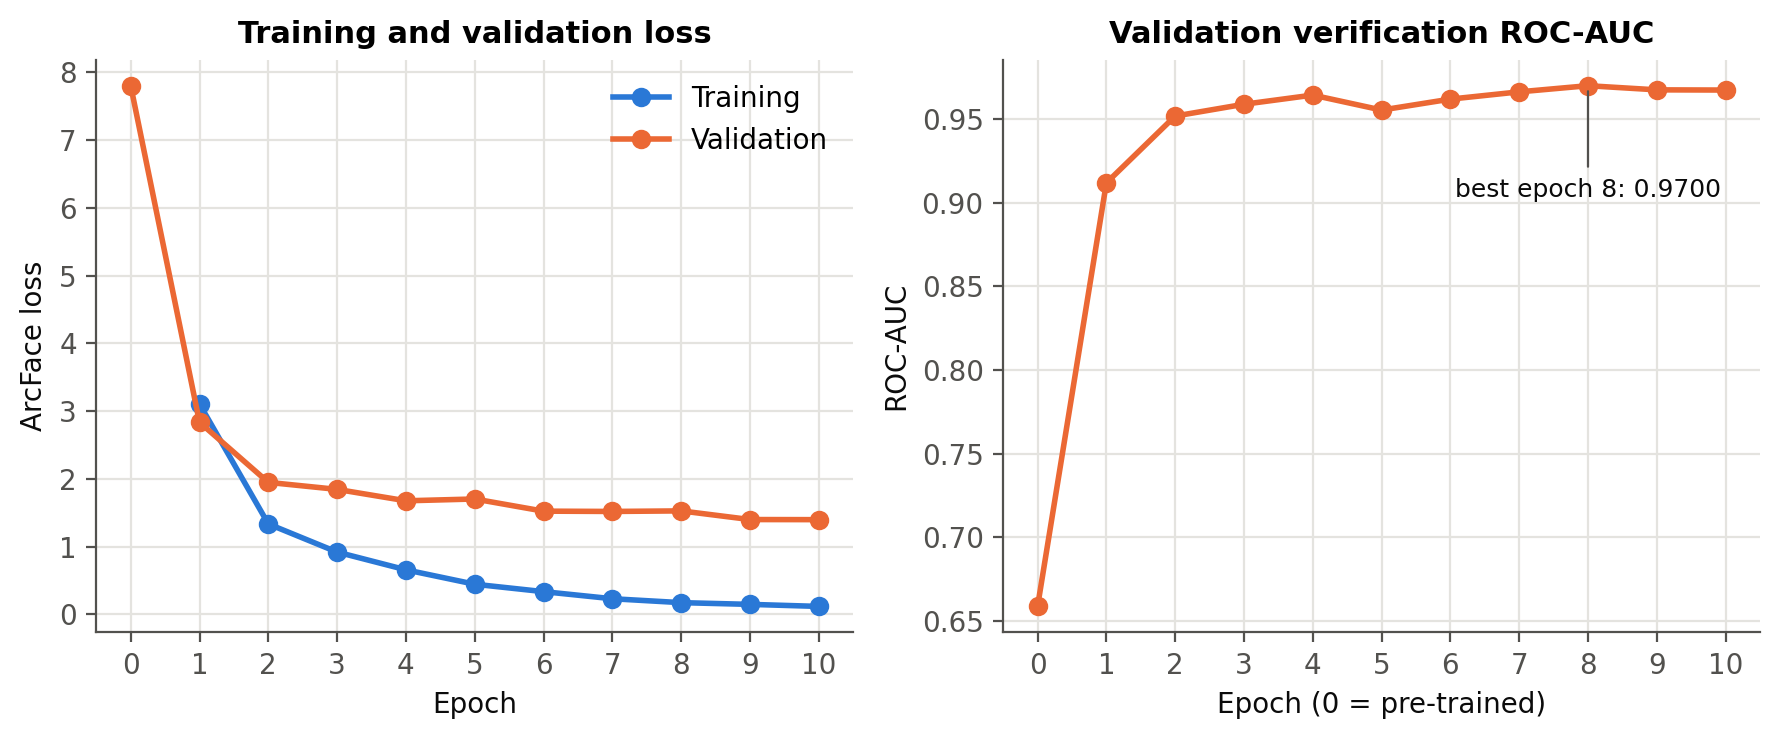

In [17]:
display(Image(filename=plot_training_history(history, CHART_DIR / "training_history.png"), width=820))

### Did the weights change?

Relative change per module between the pre-trained network and `best_model.pt`. Frozen modules should show exactly zero.

In [18]:
fine_tuned, best_checkpoint = load_embedding_model(BEST_MODEL, training_config.device)
print("best_model.pt is from epoch", best_checkpoint["epoch"])
weight_change = weight_change_summary(pretrained, fine_tuned)
weight_change.to_csv(METRICS_DIR / "weight_change.csv", index=False)
weight_change.round(5)

best_model.pt is from epoch 8


,module,parameters,relative_change
0,conv1,1792,0.00000
1,prelu,64,0.00000
2,layer1,226304,0.00000
3,layer2,1116672,0.00000
4,layer3,16270848,0.00000
5,layer4,13114880,0.10111
6,bn2,1024,0.09008
7,fc,12845568,0.65396
8,features,1024,0.00429


### KNN identity classifier

The gallery is the training subset, embedded with the fine-tuned network. Neighbour count is chosen on validation accuracy. The unknown-identity threshold is the validation-pair verification threshold: a face is rejected when no gallery face reaches the similarity at which validation pairs are best separated.

In [19]:
train_embeddings = embed_faces(fine_tuned, train_faces, detection_config, training_config.device)
validation_embeddings = embed_faces(fine_tuned, validation_faces, detection_config, training_config.device)

neighbors, neighbor_search = select_neighbors(
    train_embeddings, train_faces["identity"].to_numpy(),
    validation_embeddings, validation_faces["identity"].to_numpy(),
    training_config.knn_neighbors,
)
neighbor_search.round(4)

2026-10-23 11:52:56 [info     ] knn_neighbors_selected           [src.classifier] neighbors=15 validation_accuracy=0.9207877461706784


,neighbors,images,accuracy,macro_f1
0,1,2285,0.9094,0.8802
1,3,2285,0.9160,0.8861
2,5,2285,0.9168,0.8883
3,7,2285,0.9160,0.8876
4,9,2285,0.9190,0.8921
5,15,2285,0.9208,0.8949


In [20]:
validation_scores = pair_scores(validation_pairs, validation_faces["source_id"].to_numpy(), validation_embeddings)
unknown_threshold = select_threshold(validation_pairs["same_person"].to_numpy(), validation_scores)

knn = build_knn(neighbors).fit(train_embeddings, train_faces["identity"].to_numpy())
save_classifier(KNN_CLASSIFIER, knn, unknown_threshold, train_faces["source_id"].tolist(), BEST_MODEL, neighbor_search)
print(f"k = {neighbors}, unknown-identity threshold = {unknown_threshold:.4f} cosine similarity")

2026-10-23 11:52:56 [info     ] knn_saved                        [src.classifier] gallery=13143 neighbors=15 path=C:\Users\hafiz\face-recognition-project\checkpoints\knn_classifier.joblib


k = 15, unknown-identity threshold = 0.5398 cosine similarity


In [21]:
training_summary = {
    "device": training_config.device,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "torch_version": torch.__version__,
    "training_seconds": round(training_seconds, 1),
    "epochs_run": int(history["epoch"].max()),
    "best_epoch": int(best_checkpoint["epoch"]),
    "train_images": len(train_faces),
    "validation_images": len(validation_faces),
    "identities": identities,
    **parameter_counts,
    "knn_neighbors": neighbors,
    "unknown_threshold": unknown_threshold,
    "augmentations": list(AUGMENTATIONS),
    "config": training_config.to_dict(),
}
TRAINING_SUMMARY.write_text(json.dumps(training_summary, indent=2), encoding="utf-8")
pd.Series({key: value for key, value in training_summary.items() if not isinstance(value, (dict, list))}).to_frame("value")

,value
device,cuda
gpu,NVIDIA GeForce RTX 2050
torch_version,2.12.0+cu130
training_seconds,978.8
epochs_run,10
best_epoch,8
train_images,13143
validation_images,2285
trainable_parameters,25962496
frozen_parameters,17615680


# Part 3: Inference with the Trained Model

This part uses only files saved by Part 2, so it can run in a fresh kernel after the setup cell. `FaceRecognizer` loads `best_model.pt` and `knn_classifier.joblib`, and refuses to run if the classifier was fitted with embeddings from a different checkpoint. Test images then go through the same detection, cropping and normalisation used in training.

In [22]:
from src.config import BEST_MODEL, INFERENCE_METRICS, INFERENCE_PREDICTIONS, KNN_CLASSIFIER, CHART_DIR
from src.dataset import load_manifests
from src.inference import FaceRecognizer
from src.metrics import identification_metrics
from src.plots import plot_confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"
recognizer = FaceRecognizer(BEST_MODEL, KNN_CLASSIFIER, device=device)
print("Checkpoint epoch:", recognizer.checkpoint["epoch"], "| k =", recognizer.classifier["neighbors"],
      "| unknown threshold =", round(recognizer.classifier["unknown_threshold"], 4))

2026-10-23 11:52:57 [info     ] recognizer_loaded                [src.inference] checkpoint=best_model.pt checkpoint_epoch=8 neighbors=15 unknown_threshold=0.5398


Checkpoint epoch: 8 | k = 15 | unknown threshold = 0.5398


In [23]:
_, test_df = load_manifests()
predictions = recognizer.recognize([PROJECT_ROOT / path for path in test_df["path"]])
predictions.insert(0, "source_id", test_df["source_id"].to_numpy())
predictions.insert(1, "identity", test_df["identity"].to_numpy())
predictions.insert(2, "quality", test_df["quality"].to_numpy())
predictions["correct"] = predictions["predicted_identity"] == predictions["identity"]
predictions["detection_status"].value_counts().to_frame("test images")

2026-10-23 11:54:10 [info     ] face_detection_complete          [src.detection] detected=2008 full_image_fallback=2410 images=4418


2026-10-23 11:54:43 [info     ] recognition_complete             [src.inference] images=4418 predicted=4418 rejected_as_unknown=0


,test images
detection_status,
full_image_fallback,2410
detected,2008


### Results

Images without a usable face count as errors rather than being dropped. *Closed-set* forces a choice among the eight known people. *With rejection* also allows `unknown` when the nearest gallery face is below the threshold; since every test person is enrolled, each rejection counts as an error.

In [24]:
closed_set = predictions["closed_set_prediction"].fillna("not_processed")
accepted = predictions[~predictions["rejected_as_unknown"].astype(bool)]
inference_metrics = {
    "test_images": len(predictions),
    "images_without_usable_face": int(predictions["closed_set_prediction"].isna().sum()),
    "closed_set": identification_metrics(predictions["identity"], closed_set),
    "closed_set_by_quality": {
        quality: identification_metrics(rows["identity"], closed_set[rows.index])
        for quality, rows in predictions.groupby("quality")
    },
    "with_rejection_accuracy": float(predictions["correct"].mean()),
    "rejected_as_unknown": int(predictions["rejected_as_unknown"].astype(bool).sum()),
    "accuracy_on_accepted": float(accepted["correct"].mean()) if len(accepted) else None,
    "neighbors": recognizer.classifier["neighbors"],
    "unknown_threshold": recognizer.classifier["unknown_threshold"],
}
INFERENCE_PREDICTIONS.parent.mkdir(parents=True, exist_ok=True)
predictions.to_csv(INFERENCE_PREDICTIONS, index=False)
INFERENCE_METRICS.write_text(json.dumps(inference_metrics, indent=2), encoding="utf-8")

pd.Series({
    "closed-set accuracy": inference_metrics["closed_set"]["accuracy"],
    "closed-set macro F1": inference_metrics["closed_set"]["macro_f1"],
    "high-quality accuracy": inference_metrics["closed_set_by_quality"]["high_quality"]["accuracy"],
    "low-quality accuracy": inference_metrics["closed_set_by_quality"]["low_quality"]["accuracy"],
    "accuracy with rejection": inference_metrics["with_rejection_accuracy"],
    "rejected as unknown": inference_metrics["rejected_as_unknown"],
    "accuracy on accepted faces": inference_metrics["accuracy_on_accepted"],
}).round(4).to_frame("value")

,value
closed-set accuracy,0.9140
closed-set macro F1,0.8848
high-quality accuracy,0.9907
low-quality accuracy,0.8954
accuracy with rejection,0.9140
rejected as unknown,0.0000
accuracy on accepted faces,0.9140


In [25]:
predictions.sample(12, random_state=7)[
    ["source_id", "identity", "predicted_identity", "nearest_similarity", "correct"]
].rename(columns={
    "source_id": "Image", "identity": "Actual identity", "predicted_identity": "Predicted identity",
    "nearest_similarity": "Nearest similarity", "correct": "Correct",
}).round(3)

,Image,Actual identity,Predicted identity,Nearest similarity,Correct
889,firoz_hq_frame111_face112_jpg,firoz,firoz,0.994,True
4123,suresh_lq_f_6550_png,suresh,suresh,0.976,True
2985,suresh_lq_f_1049_png,suresh,suresh,0.976,True
3350,suresh_lq_f_2477_png,suresh,suresh,0.951,True
1457,mujeeb_lq_b_578_png,mujeeb,mujeeb,0.942,True
652,ananthu_lq_t_2126_png,ananthu,ananthu,0.876,True
161,ananthu_lq_t_117_png,ananthu,ananthu,0.943,True
4092,suresh_lq_f_6519_png,suresh,suresh,0.987,True
2183,sebin_lq_d_1652_png,sebin,shinjil,0.906,False
737,ananthu_lq_t_2935_png,ananthu,ananthu,0.994,True


In [26]:
per_identity = predictions.assign(closed_set_correct=closed_set == predictions["identity"]).pivot_table(
    index="identity", columns="quality", values="closed_set_correct", aggfunc="mean"
)
per_identity.round(3)

quality,high_quality,low_quality
identity,,
ananthu,0.952,0.948
firoz,1.000,0.740
mujeeb,1.000,0.795
ruvais,1.000,0.855
sebin,0.988,0.834
shinjil,1.000,0.809
suresh,1.000,0.977
thomas,1.000,0.623


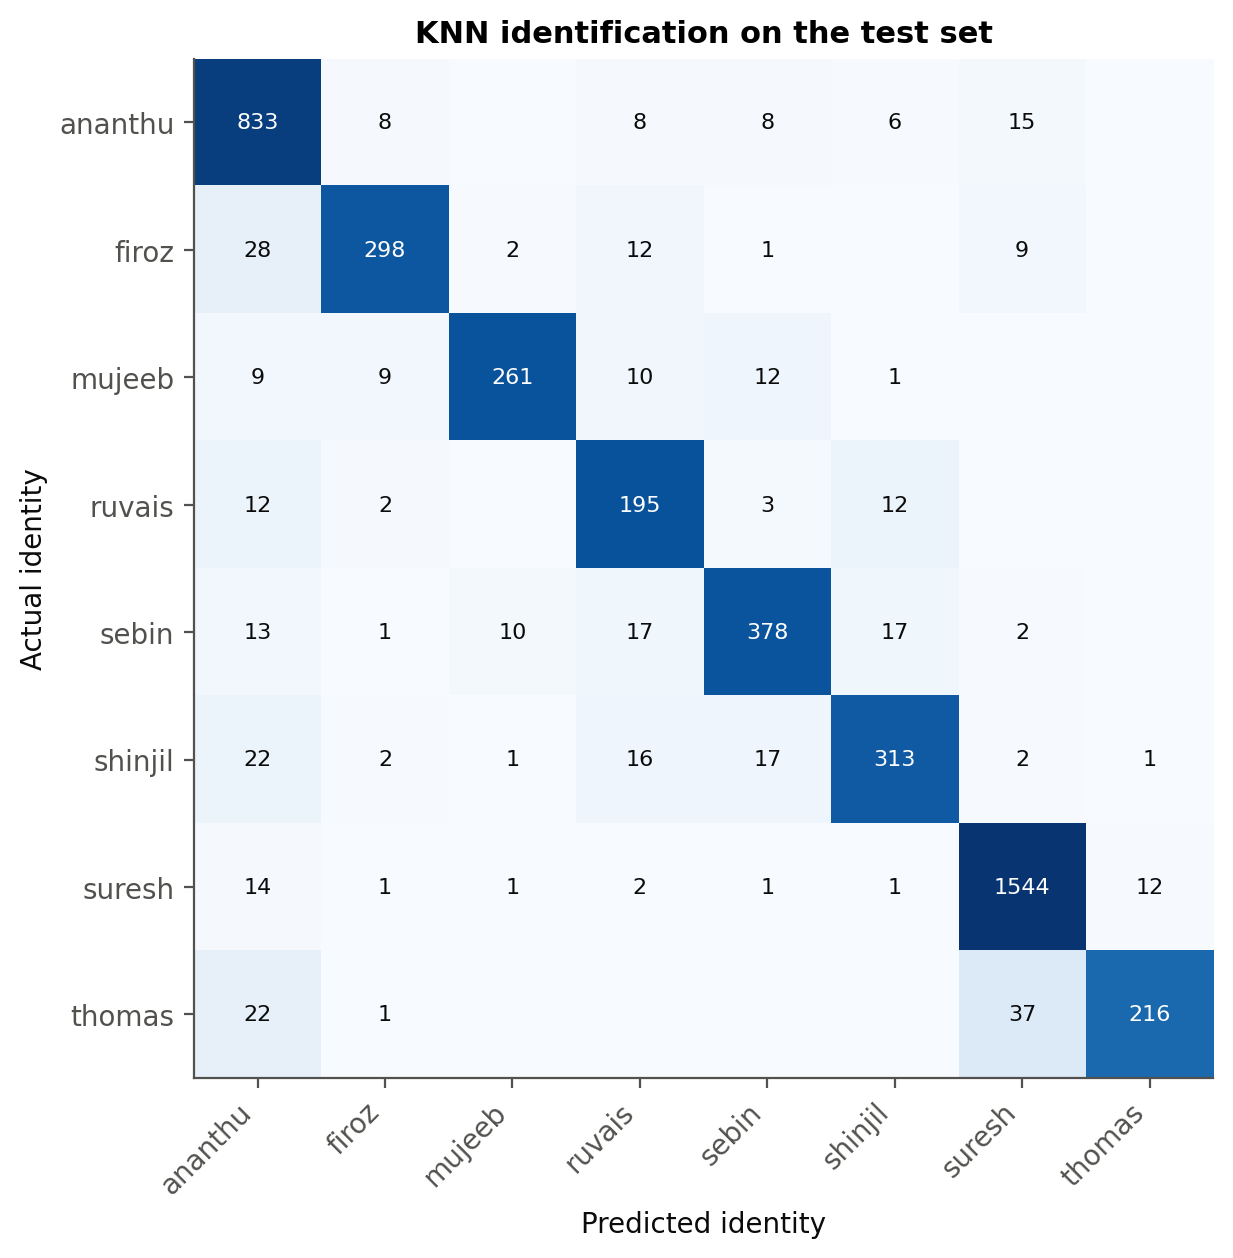

In [27]:
identities = sorted(predictions["identity"].unique())
display(Image(filename=plot_confusion_matrix(
    predictions["identity"], closed_set, identities + (["not_processed"] if (closed_set == "not_processed").any() else []),
    CHART_DIR / "knn_confusion_matrix.png", "KNN identification on the test set",
), width=520))

Next: `python -m scripts.final_evaluation`, then `python -m scripts.check_data_leakage`, then `python -m scripts.generate_report`.